In [3]:
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import plotly.express as px
import folium

from tqdm import tqdm
from pathlib import Path


In [4]:
citibike_df = pd.concat(dfs)
citibike_df.head()

NameError: name 'dfs' is not defined

In [ ]:
citibike_df.shape

(1002704, 13)

In [ ]:
citibike_df['started_at'] = pd.to_datetime(citibike_df['started_at'],errors="coerce")
citibike_df['ended_at'] = pd.to_datetime(citibike_df['ended_at'],errors="coerce")

citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member


In [ ]:
citibike_df.info()

<class 'pandas.DataFrame'>
Index: 1002704 entries, 0 to 48473
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   ride_id             1002704 non-null  str           
 1   rideable_type       1002704 non-null  str           
 2   started_at          1002704 non-null  datetime64[us]
 3   ended_at            1002704 non-null  datetime64[us]
 4   start_station_name  1002701 non-null  str           
 5   start_station_id    1002701 non-null  str           
 6   end_station_name    999469 non-null   str           
 7   end_station_id      998307 non-null   str           
 8   start_lat           1002702 non-null  float64       
 9   start_lng           1002702 non-null  float64       
 10  end_lat             999260 non-null   float64       
 11  end_lng             999260 non-null   float64       
 12  member_casual       1002704 non-null  str           
dtypes: datetime64[us](2), float64(

In [ ]:
missing_values = (
    citibike_df
    .isna()
    .sum()
    .reset_index()
)

missing_values.columns = ["column", "missing_count"]

missing_values["missing_share"] = (
    missing_values["missing_count"] / len(citibike_df)
)

missing_values.sort_values("missing_count", ascending=False)

,column,missing_count,missing_share
7,end_station_id,4397,0.004385
10,end_lat,3444,0.003435
11,end_lng,3444,0.003435
6,end_station_name,3235,0.003226
4,start_station_name,3,0.000003
5,start_station_id,3,0.000003
8,start_lat,2,0.000002
9,start_lng,2,0.000002
0,ride_id,0,0.000000
3,ended_at,0,0.000000


In [ ]:
citibike_df = citibike_df.dropna(
    subset=[
        "ride_id",
        "started_at",
        "ended_at",
        "start_lat",
        "start_lng",
        "end_lat",
        "end_lng"
    ]
)

In [ ]:
citibike_df.shape

(999258, 13)

In [ ]:
citibike_df["ride_duration_minutes"] = (
    citibike_df["ended_at"] - citibike_df["started_at"]
).dt.total_seconds() / 60

In [ ]:
citibike_df = citibike_df[
    (citibike_df["ride_duration_minutes"] > 1) &
    (citibike_df["ride_duration_minutes"] <= 24 * 60)
].copy()

In [ ]:
citibike_df.shape

(999225, 14)

In [ ]:
citibike_df["date"] = citibike_df["started_at"].dt.date
citibike_df["month"] = citibike_df["started_at"].dt.to_period("M").astype(str)
citibike_df["month_name"] = citibike_df["started_at"].dt.month_name()
citibike_df["day_of_week"] = citibike_df["started_at"].dt.day_name()
citibike_df["hour"] = citibike_df["started_at"].dt.hour

In [ ]:
def assign_season(month_number):
    if month_number in [12, 1, 2]:
        return "Winter"
    elif month_number in [3, 4, 5]:
        return "Spring"
    elif month_number in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


citibike_df["season"] = (
    citibike_df["started_at"]
    .dt.month
    .apply(assign_season)
)

In [ ]:
citibike_df.to_csv('../data/citibike/JC/JC2025_Enriched.csv', index= False)

In [ ]:
citibike_df.shape

(999225, 20)

In [ ]:
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes,date,month,month_name,day_of_week,hour,season
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,6.192900,2025-01-16,2025-01,January,Thursday,17,Winter
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,11.461350,2025-01-31,2025-01,January,Friday,6,Winter
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,21.377617,2025-01-09,2025-01,January,Thursday,16,Winter
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,22.934333,2025-01-21,2025-01,January,Tuesday,16,Winter
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,25.822100,2025-01-30,2025-01,January,Thursday,16,Winter


In [ ]:
mothly_rides = (
    citibike_df
    .groupby("month", as_index = False)
    .agg ( number_of_rides = ("ride_id", "count"))
)

In [ ]:
mothly_rides

,month,number_of_rides
0,2024-12,2
1,2025-01,50589
2,2025-02,45250
3,2025-03,73277
4,2025-04,81533
5,2025-05,93202
6,2025-06,96736
7,2025-07,107374
8,2025-08,108001
9,2025-09,115580


In [ ]:
import pandas as pd
import requests

lat = 40.7178
lng = -74.0431

start_date = "2025-01-01"
end_date = "2025-12-31"

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lng,
    "start_date": start_date,
    "end_date": end_date,
    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "precipitation_sum",
        "rain_sum",
        "snowfall_sum",
        "wind_speed_10m_max"
    ],
    "timezone": "America/New_York"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

weather_daily = pd.DataFrame(data["daily"])
weather_daily["date"] = pd.to_datetime(weather_daily["time"])
weather_daily = weather_daily.drop(columns="time")

weather_daily.tail()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,date
360,-1.0,-7.3,-3.6,5.3,0.4,3.43,16.3,2025-12-27
361,1.0,-11.6,-5.8,0.9,0.9,0.00,9.4,2025-12-28
362,7.3,-1.4,3.5,3.9,3.9,0.00,23.8,2025-12-29
363,-0.2,-3.0,-1.3,0.0,0.0,0.00,25.5,2025-12-30
364,-0.2,-3.7,-2.2,0.0,0.0,0.00,16.5,2025-12-31


In [ ]:
weather_daily.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   temperature_2m_max   365 non-null    float64       
 1   temperature_2m_min   365 non-null    float64       
 2   temperature_2m_mean  365 non-null    float64       
 3   precipitation_sum    365 non-null    float64       
 4   rain_sum             365 non-null    float64       
 5   snowfall_sum         365 non-null    float64       
 6   wind_speed_10m_max   365 non-null    float64       
 7   date                 365 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(7)
memory usage: 22.9 KB


In [ ]:
list(weather_daily.columns)

['temperature_2m_max',
 'temperature_2m_min',
 'temperature_2m_mean',
 'precipitation_sum',
 'rain_sum',
 'snowfall_sum',
 'wind_speed_10m_max',
 'date']

In [ ]:
weather_daily = weather_daily [['date','temperature_2m_max',
 'temperature_2m_min',
 'temperature_2m_mean',
 'precipitation_sum',
 'rain_sum',
 'snowfall_sum',
 'wind_speed_10m_max']]

In [ ]:
weather_daily.head()

,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,2025-01-01,10.9,3.9,7.4,4.5,4.5,0.0,23.2
1,2025-01-02,5.4,0.3,2.6,0.0,0.0,0.0,25.1
2,2025-01-03,3.2,-1.9,0.4,0.0,0.0,0.0,17.1
3,2025-01-04,-0.1,-2.7,-1.4,0.0,0.0,0.0,26.1
4,2025-01-05,0.3,-3.6,-2.2,0.0,0.0,0.0,19.9


In [ ]:
citibike_df['date'] = pd.to_datetime(citibike_df['date'],errors="coerce")


In [ ]:
citibike_df.info()

<class 'pandas.DataFrame'>
Index: 999225 entries, 0 to 48473
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   ride_id                999225 non-null  str           
 1   rideable_type          999225 non-null  str           
 2   started_at             999225 non-null  datetime64[us]
 3   ended_at               999225 non-null  datetime64[us]
 4   start_station_name     999224 non-null  str           
 5   start_station_id       999224 non-null  str           
 6   end_station_name       998439 non-null  str           
 7   end_station_id         998282 non-null  str           
 8   start_lat              999225 non-null  float64       
 9   start_lng              999225 non-null  float64       
 10  end_lat                999225 non-null  float64       
 11  end_lng                999225 non-null  float64       
 12  member_casual          999225 non-null  str           
 13  r

In [ ]:
daily_rides = (
    citibike_df
    .groupby("date", as_index=False)
    .agg(
        number_of_rides=("ride_id", "count")
    )
)
daily_rides["date"] = pd.to_datetime(daily_rides["date"])
daily_rides.head()

,date,number_of_rides
0,2024-12-31,2
1,2025-01-01,1179
2,2025-01-02,1710
3,2025-01-03,1770
4,2025-01-04,1337


In [ ]:
bike_weather_daily = daily_rides.merge(
    weather_daily,
    on="date",
    how="left"
)
bike_weather_daily

,date,number_of_rides,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,2024-12-31,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-01-01,1179,10.9,3.9,7.4,4.5,4.5,0.00,23.2
2,2025-01-02,1710,5.4,0.3,2.6,0.0,0.0,0.00,25.1
3,2025-01-03,1770,3.2,-1.9,0.4,0.0,0.0,0.00,17.1
4,2025-01-04,1337,-0.1,-2.7,-1.4,0.0,0.0,0.00,26.1
...,...,...,...,...,...,...,...,...,...
361,2025-12-27,287,-1.0,-7.3,-3.6,5.3,0.4,3.43,16.3
362,2025-12-28,488,1.0,-11.6,-5.8,0.9,0.9,0.00,9.4
363,2025-12-29,952,7.3,-1.4,3.5,3.9,3.9,0.00,23.8
364,2025-12-30,1142,-0.2,-3.0,-1.3,0.0,0.0,0.00,25.5


In [ ]:
temperature_long = weather_daily.melt(
    id_vars= 'date',
    value_vars =  [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean"
    ],
    var_name =  "temperature_type",
    value_name = "temperature"
)

temperature_long

,date,temperature_type,temperature
0,2025-01-01,temperature_2m_max,10.9
1,2025-01-02,temperature_2m_max,5.4
2,2025-01-03,temperature_2m_max,3.2
3,2025-01-04,temperature_2m_max,-0.1
4,2025-01-05,temperature_2m_max,0.3
...,...,...,...
1090,2025-12-27,temperature_2m_mean,-3.6
1091,2025-12-28,temperature_2m_mean,-5.8
1092,2025-12-29,temperature_2m_mean,3.5
1093,2025-12-30,temperature_2m_mean,-1.3


In [6]:
import geopandas as gpd
from urllib.parse import urlencode
from pathlib import Path


url = '../data/citibike/JC/jersey-city-neighborhoods.geojson'

jersey_city = gpd.read_file(url)

jersey_city.head()

,cartodb_id,area_sq_ft,acres,area,neighborhood,color,lon,lat,geometry
0,38,411601381.8,9449.068,Greenville,Port Liberte,NaN,-74.074540,40.694202,"POLYGON ((-74.06862 40.70098, -74.06808 40.696..."
1,52,411601381.8,9449.068,Bergen-Lafayette,LSP Industrial,NaN,-74.062358,40.699189,"POLYGON ((-74.06808 40.69684, -74.06862 40.700..."
2,29,411601381.8,9449.068,West Side,Hackensack,NaN,-74.085147,40.735520,"POLYGON ((-74.07601 40.73822, -74.07781 40.737..."
3,35,411601381.8,9449.068,Bergen-Lafayette,Lafayette,12.0,-74.061279,40.712676,"POLYGON ((-74.056 40.71735, -74.056 40.71692, ..."
4,51,411601381.8,9449.068,Greenville,Jackson Hill,15.0,-74.085503,40.700791,"POLYGON ((-74.07561 40.70233, -74.0758 40.7020..."


In [7]:
jersey_city.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   cartodb_id    53 non-null     int32   
 1   area_sq_ft    53 non-null     float64 
 2   acres         53 non-null     float64 
 3   area          53 non-null     str     
 4   neighborhood  53 non-null     str     
 5   color         18 non-null     float64 
 6   lon           53 non-null     float64 
 7   lat           53 non-null     float64 
 8   geometry      53 non-null     geometry
dtypes: float64(5), geometry(1), int32(1), str(2)
memory usage: 4.8 KB


In [8]:
jersey_city.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [9]:
jersey_city = jersey_city.to_crs("EPSG:4326")

<Axes: >

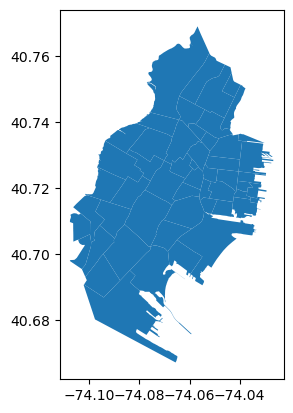

In [10]:
jersey_city.plot()

In [ ]:
citibike_df = pd.read_csv('../data/citibike/JC/JC2025_Enriched.csv')

In [ ]:
citibike_df

In [ ]:
start_stations = citibike_df[
    [
        "ride_id",
        "start_station_id",
        "start_station_name",
        "start_lat",
        "start_lng"
    ]
].copy()

In [ ]:
start_stations = start_stations.rename(
    columns={
        "start_station_id": "station_id",
        "start_station_name": "station_name",
        "start_lat": "lat",
        "start_lng": "lng"
    }
)

start_stations["activity_type"] = "departure"